# R-MOVE · Notebook temporal: ¿qué otras incidencias reducen los viajes a Barcelona?

**Objetivo.** Probar las incidencias candidatas de la lista de Twitter (grupos **A · prioritarias** y **B · posibles**,
ver `claude/incidencias_candidatas_twitter.md`) con el mismo método que el notebook 04 (clustering + corrección por el
control + placebos) y decidir cuáles se añaden al notebook principal.

**Es un notebook de pruebas:** no modifica ni exporta nada. Lee los ficheros que ya genera el 04.

**Criterio para añadir una incidencia al 04 (fijado antes de ver los resultados):**
1. Los municipios **dependientes de las líneas afectadas** caen de forma clara (p < 0,05).
2. Sigue siendo clara después de corregir por hacer muchas pruebas a la vez (q de Benjamini-Hochberg < 0,10).
3. Los dependientes de las **líneas no afectadas** no caen de forma clara (si caen todos, no es la incidencia).

## 0. Configuración

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow.parquet as pq
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
pd.set_option("display.max_rows", 100); pd.set_option("display.width", 200)

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, RAW = ROOT / "data" / "processed", ROOT / "data" / "raw"
OUT = PROC / "rmove"
F_M2, F_INC_OFICIAL = PROC / "telefonica" / "M2.parquet", RAW / "rodalies" / "incidencias_rodalies_2023_2025.csv"
INICIO, FIN, BCN_CODE, SEGMENTOS, K_VOL = "2023-01-01", "2025-08-31", "08019", ["Regional", "Residente"], 4

# Días de caos del notebook 04 (se muestran como referencia)
CAOS_04 = {"2024-05-13": "Avería: robo de cobre en Montcada (día 1)", "2025-03-17": "Huelga (caos generalizado)",
           "2025-03-26": "Huelga 24 h", "2025-04-01": "Huelga 24 h"}

# Cortes largos: el registro oficial solo marca el primer día (misma regla que el 04 revisado)
CORTES_LARGOS = (pd.date_range("2023-05-02", "2023-05-19")
                 .union(pd.date_range("2024-05-13", "2024-06-14"))
                 .union(pd.date_range("2025-04-28", "2025-04-30")))

# R4 Nord: municipios dependientes de la R4 al norte de Barcelona (el resto de la R4 es R4 Sud, Penedès)
R4_NORD = {"Castellbell i el Vilar", "Sant Vicenç de Castellet", "Vacarisses", "Viladecavalls"}

### Incidencias candidatas

`lineas` = líneas afectadas, con la R4 separada en **R4N** (Vallès–Bages) y **R4S** (Penedès).
Las líneas sin municipios dependientes (R7, R8, regionales) no se ponen. Si cambiáis alguna línea o fecha, hacedlo aquí.

In [2]:
CANDIDATAS = pd.DataFrame([
    # fecha,       grupo, descripción,                                                        líneas afectadas
    ("2023-05-02", "A", "Gavà día 1: incendio del enclavamiento, R2 Sud con servicio reducido", ["R2S"]),
    ("2024-02-06", "A", "Doble avería de señalización túnel Pl. Catalunya–Arc de Triomf (7:30–11)", ["R1", "R3", "R4N", "R4S"]),
    ("2024-02-21", "A", "Robo de cobre en Cerdanyola (6–14 h)",                                 ["R4N"]),
    ("2024-04-04", "A", "Señalización/robo L'Hospitalet–Arc de Triomf (7–11:30)",              ["R1", "R4N", "R4S"]),
    ("2024-05-03", "A", "Robo de cobre Mollet–Granollers (6–11:30)",                            ["R2N"]),
    ("2024-09-16", "A", "Instalaciones Pl. Catalunya–Fabra i Puig (desde 6:45)",               ["R1", "R3", "R4N", "R4S"]),
    ("2025-03-31", "A", "Electrificación Castellbisbal (R4) y Mollet (R2N), 2 trenes/h",       ["R4S", "R2N"]),
    ("2023-03-14", "B", "Sin suministro eléctrico Sants–Castellbisbal (~6:40)",                ["R1", "R3", "R4N", "R4S"]),
    ("2024-03-18", "B", "Enclavamiento El Prat (7–10 h); el tuit decía R4: fuentes contradictorias", ["R2S"]),
    ("2024-11-11", "B", "Avería en Sants (desde 7:55)",                                        ["R1", "R3", "R4N", "R4S"]),
    ("2024-11-22", "B", "Robo de cobre R4 Sabadell–Terrassa (desde el inicio del servicio)",   ["R4N"]),
    ("2024-12-18", "B", "Atropello El Prat (R2, 7–13:30) + Pl. Catalunya (R1/R3/R4, 8:25–11:40)", ["R2N", "R2S", "R1", "R3", "R4N", "R4S"]),
    ("2024-12-19", "B", "Instalaciones Castelldefels (R2, 5–9:45)",                            ["R2N", "R2S"]),
    ("2025-01-10", "B", "R2 Sud con 2 trenes/h (7:30–10:30)",                                  ["R2S"]),
    ("2025-02-11", "B", "Robo de cable R2N + avería Arenys–Mataró (R1)",                       ["R2N", "R1"]),
    ("2025-04-10", "B", "Vía única Castellbisbal (R4) + Fabra i Puig (R3/R4)",                 ["R3", "R4N", "R4S"]),
    ("2025-05-08", "B", "Registro oficial: R2 todo el día (sin detalle)",                      ["R2N", "R2S"]),
    ("2025-05-14", "B", "R2 Sud con 2 trenes/h (Gavà–El Prat, mañana)",                        ["R2S"]),
], columns=["fecha", "grupo", "descripcion", "lineas"])
CANDIDATAS["fecha"] = pd.to_datetime(CANDIDATAS.fecha)
CAOS = pd.DataFrame({"fecha": pd.to_datetime(list(CAOS_04)), "grupo": "Caos (04)", "descripcion": list(CAOS_04.values()),
                     "lineas": [["R1", "R2N", "R2S", "R3", "R4N", "R4S"]] * len(CAOS_04)})
DIAS = pd.concat([CAOS, CANDIDATAS], ignore_index=True)
print(len(CANDIDATAS), "candidatas:", CANDIDATAS.grupo.value_counts().to_dict())

18 candidatas: {'B': 11, 'A': 7}


## 1. Datos

In [3]:
cal  = pd.read_parquet(OUT / "m2_cal.parquet")                 # calendario del 04 (finde, festivos, verano, eventos, lluvia…)
info = pd.read_parquet(OUT / "m2_info_municipios.parquet")     # grupos de municipios del 04
ctrl = list(pd.read_parquet(OUT / "m2_ctrl_codes.parquet").municipio_code)

cols = ["day", "origen", "municipio_origen", "municipio_destino", "viajes"]
mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", BCN_CODE)]).to_pandas()
if mov.empty:
    mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", int(BCN_CODE))]).to_pandas()
mov["municipio_origen"] = mov.municipio_origen.astype(str).str.zfill(5)
mov = mov[(mov.municipio_origen != BCN_CODE) & mov.origen.isin(SEGMENTOS)]
mov["fecha"] = pd.to_datetime(mov.day)
mov = mov[(mov.fecha >= INICIO) & (mov.fecha <= FIN)]
V_all = (mov.groupby(["fecha", "municipio_origen"]).viajes.sum().unstack().astype(float)
           .reindex(columns=info.index).where(lambda x: x > 0))
print(V_all.shape, "| días sin datos de Telefónica entre las candidatas:",
      [f"{d:%d/%m/%Y}" for d in DIAS.fecha if d not in V_all.index])

(971, 133) | días sin datos de Telefónica entre las candidatas: []


**Comprobación de las fechas.** Las candidatas deben ser laborables, fuera de verano, sin lluvia y sin eventos (`base_ok`).
Las huelgas del 04 salen como «evento» porque están en la lista de huelgas: es normal.

In [4]:
chk = cal.reindex(DIAS.fecha)[["finde", "festivo", "puente", "verano", "evento", "mal_tiempo", "lluvia_pond", "base_ok"]]
display(chk.assign(grupo=DIAS.grupo.values).round(1))
assert chk.base_ok[DIAS.grupo.isin(["A", "B"]).values].all(), "Hay alguna candidata que no pasa los filtros: revisadla"

,finde,festivo,puente,verano,evento,mal_tiempo,lluvia_pond,base_ok,grupo
fecha,,,,,,,,,
2024-05-13,False,False,False,False,False,False,0.0,True,Caos (04)
2025-03-17,False,False,False,False,True,False,0.5,False,Caos (04)
2025-03-26,False,False,False,False,True,False,0.4,False,Caos (04)
2025-04-01,False,False,False,False,True,False,0.1,False,Caos (04)
2023-05-02,False,False,False,False,False,False,0.0,True,A
2024-02-06,False,False,False,False,False,False,0.0,True,A
2024-02-21,False,False,False,False,False,False,0.0,True,A
2024-04-04,False,False,False,False,False,False,0.0,True,A
2024-05-03,False,False,False,False,False,False,0.0,True,A


### Días limpios (referencia)

Misma regla que el 04 revisado: días laborables sin festivos, verano, eventos ni mal tiempo (`base_ok`), sin incidencia de
**Rodalies BCN** en el registro oficial y fuera de los **cortes largos**. Además, **todas las candidatas y los días de caos
se quitan de la referencia**: un día o es de incidencia o es normal, nunca las dos cosas.

In [5]:
inc_of = pd.read_csv(F_INC_OFICIAL, parse_dates=["fecha"])
dias_inc_oficial = pd.DatetimeIndex(inc_of[inc_of.servicio == "rodalies_bcn"].fecha.unique())

cal["limpio"] = (cal.base_ok & ~cal.index.isin(dias_inc_oficial) & ~cal.index.isin(CORTES_LARGOS)
                 & ~cal.index.isin(DIAS.fecha))
LIMPIOS = cal.index[cal.limpio].intersection(V_all.index)
V = V_all.loc[LIMPIOS.union(DIAS.fecha)]
print("Días limpios por año:", pd.Series(LIMPIOS.year).value_counts().sort_index().to_dict())
print("Candidatas que ya estaban en el registro oficial:",
      [f"{d:%d/%m/%y}" for d in CANDIDATAS.fecha if d in dias_inc_oficial])

Días limpios por año: {2023: 118, 2024: 89, 2025: 55}
Candidatas que ya estaban en el registro oficial: ['02/05/23', '31/03/25', '19/12/24', '10/01/25', '11/02/25', '10/04/25', '08/05/25']


## 2. Método (igual que el 04)

- **Tipo de día:** K-means (k = 4) por año sobre los días limpios, con el log del volumen de los municipios sin Rodalies
  y la época del año.
- **Efecto:** (viajes del grupo / su mediana en los días limpios del mismo tipo) ÷ (lo mismo para el control) − 1.
- **p y margen de error:** placebos (cada día limpio tratado como falso día de caos, con el clustering reentrenado sin él).
  p unilateral: ¿cae más que los días normales?

In [6]:
vol_ctrl = np.log(V_all[ctrl].sum(axis=1, min_count=len(ctrl) // 2))   # todos los días (el clustering solo se entrena con los limpios)
s_ctrl = V_all[ctrl].sum(axis=1, min_count=1)
_pct = lambda x: (np.exp(x) - 1) * 100

def variables_dia(dias):
    dias = pd.DatetimeIndex(dias)
    return pd.DataFrame({"vol": vol_ctrl.reindex(dias).values, "epoca": dias.day_of_year / 365}, index=dias)

def ajustar_tipos(dias):
    return make_pipeline(StandardScaler(), KMeans(K_VOL, n_init=10, random_state=0)).fit(variables_dia(dias))

modelos = {}
for y in sorted(LIMPIOS.year.unique()):
    dias = LIMPIOS[LIMPIOS.year == y].intersection(vol_ctrl.dropna().index)
    modelos[y] = (ajustar_tipos(dias), dias)

def dias_mismo_tipo(d):
    pipe, dias = modelos[d.year]
    return dias[pipe[-1].labels_ == pipe.predict(variables_dia([d]))[0]]

# Placebos leave-one-out (tarda 1–2 minutos)
REF_LOO = {}
for y, (_, dias) in modelos.items():
    for d in dias:
        resto = dias.drop(d); p_ = ajustar_tipos(resto)
        REF_LOO[d] = resto[p_[-1].labels_ == p_.predict(variables_dia([d]))[0]]
print(len(REF_LOO), "días limpios con placebo")

262 días limpios con placebo


In [7]:
def _ef_log(s, d, ref):
    return np.log(s.loc[d] / s.loc[ref].median()) - np.log(s_ctrl.loc[d] / s_ctrl.loc[ref].median())

_cache = {}
def placebos(codes):
    key = tuple(sorted(codes))
    if key not in _cache:
        s = V[list(key)].sum(axis=1, min_count=1)
        p = np.array([_ef_log(s, d, r) for d, r in REF_LOO.items()])
        _cache[key] = p[np.isfinite(p)]
    return _cache[key]

def efecto_dia(codes, d):
    # Efecto % del día d, p unilateral (caída) e IC95 a partir de los placebos del mismo grupo
    if len(codes) == 0:
        return dict(efecto=np.nan, p=np.nan, lo=np.nan, hi=np.nan)
    s = V[codes].sum(axis=1, min_count=1)
    e = _ef_log(s, d, dias_mismo_tipo(d)); pl = placebos(codes)
    return dict(efecto=_pct(e), p=(1 + (pl <= e).sum()) / (len(pl) + 1),
                lo=_pct(e - np.quantile(pl, .975)), hi=_pct(e - np.quantile(pl, .025)))

# Municipios dependientes por línea (R4 separada en Nord y Sud)
dep = info[info.dependiente].copy()
def lineas_mun(r):
    ls = set(r.lineas.split("+"))
    if "R4" in ls:
        ls = (ls - {"R4"}) | {"R4N" if r.municipio in R4_NORD else "R4S"}
    return ls
dep["L"] = dep.apply(lineas_mun, axis=1)
display(dep.explode("L").groupby("L").municipio.apply(lambda s: f"{len(s)}: " + ", ".join(sorted(s))).to_frame("dependientes"))

,dependientes
L,
R1,"12: Arenys de Mar, Cabrera de Mar, Caldes d'Es..."
R2N,"6: Cardedeu, Franqueses del Vallès, Les, Grano..."
R2S,"4: Castelldefels, Cubelles, Sitges, Vilanova i..."
R3,"7: Balenyà, Centelles, Franqueses del Vallès, ..."
R4N,"4: Castellbell i el Vilar, Sant Vicenç de Cast..."
R4S,"4: Gelida, Sant Sadurní d'Anoia, Subirats, Vil..."


## 3. Resultados día a día

Para cada día se calcula el efecto en tres grupos de municipios dependientes (≥ 20 km, sin metro/FGC):
- **Líneas afectadas:** el grupo que debería caer.
- **Líneas no afectadas:** comprobación (no debería caer).
- **Todos los dependientes:** para comparar con el notebook 04.

In [8]:
filas = []
for _, r in DIAS.iterrows():
    afect = list(dep.index[dep.L.map(lambda s: bool(s & set(r.lineas)))])
    no_af = list(dep.index[dep.L.map(lambda s: not (s & set(r.lineas)))])
    ea, en, et = efecto_dia(afect, r.fecha), efecto_dia(no_af, r.fecha), efecto_dia(list(dep.index), r.fecha)
    filas.append({"fecha": r.fecha, "grupo": r.grupo, "descripcion": r.descripcion, "lineas": "+".join(r.lineas),
                  "n_afect": len(afect), "afect_%": ea["efecto"], "afect_p": ea["p"], "afect_lo": ea["lo"], "afect_hi": ea["hi"],
                  "n_no_afect": len(no_af), "no_afect_%": en["efecto"], "no_afect_p": en["p"],
                  "todos_%": et["efecto"], "todos_p": et["p"]})
res = pd.DataFrame(filas)

# Corrección por pruebas múltiples (Benjamini-Hochberg) solo entre las candidatas
m = res.grupo.isin(["A", "B"])
p = res.loc[m, "afect_p"].values; orden = np.argsort(p); n = len(p)
q = np.empty(n); q[orden] = np.minimum.accumulate((p[orden] * n / np.arange(1, n + 1))[::-1])[::-1]
res.loc[m, "afect_q"] = np.minimum(q, 1)

res["veredicto"] = np.select(
    [res.grupo.str.startswith("Caos"),
     (res.afect_p < .05) & (res.afect_q < .10) & ~((res.no_afect_p < .05) & (res["no_afect_%"] < 0)),
     (res.afect_p < .05) & (res.no_afect_p < .05) & (res["no_afect_%"] < 0),
     res.afect_p < .05],
    ["referencia", "✅ añadir", "⚠️ caen todos", "🔶 al límite (no pasa la corrección)"], "❌ sin efecto claro")

display(res.assign(fecha=res.fecha.dt.strftime("%d/%m/%Y"))
          [["fecha", "grupo", "lineas", "n_afect", "afect_%", "afect_p", "afect_q", "no_afect_%", "no_afect_p", "todos_%", "veredicto"]]
          .round({"afect_%": 1, "afect_p": 3, "afect_q": 3, "no_afect_%": 1, "no_afect_p": 3, "todos_%": 1}))

,fecha,grupo,lineas,n_afect,afect_%,afect_p,afect_q,no_afect_%,no_afect_p,todos_%,veredicto
0,13/05/2024,Caos (04),R1+R2N+R2S+R3+R4N+R4S,35,-10.4,0.008,NaN,NaN,NaN,-10.4,referencia
1,17/03/2025,Caos (04),R1+R2N+R2S+R3+R4N+R4S,35,-8.9,0.011,NaN,NaN,NaN,-8.9,referencia
2,26/03/2025,Caos (04),R1+R2N+R2S+R3+R4N+R4S,35,1.8,0.715,NaN,NaN,NaN,1.8,referencia
3,01/04/2025,Caos (04),R1+R2N+R2S+R3+R4N+R4S,35,-6.8,0.023,NaN,NaN,NaN,-6.8,referencia
4,02/05/2023,A,R2S,4,-11.8,0.027,0.228,-0.9,0.407,-4.3,🔶 al límite (no pasa la corrección)
5,06/02/2024,A,R1+R3+R4N+R4S,27,1.1,0.646,0.876,0.6,0.544,1.1,❌ sin efecto claro
6,21/02/2024,A,R4N,4,3.5,0.692,0.876,4.6,0.935,4.5,❌ sin efecto claro
7,04/04/2024,A,R1+R4N+R4S,20,2.0,0.730,0.876,-1.8,0.285,0.4,❌ sin efecto claro
8,03/05/2024,A,R2N,6,-1.8,0.323,0.753,-3.3,0.137,-3.0,❌ sin efecto claro
9,16/09/2024,A,R1+R3+R4N+R4S,27,3.6,0.856,0.914,5.8,0.928,3.7,❌ sin efecto claro


**Cómo leer la tabla.** `afect_%` es el cambio de viajes en los dependientes de las líneas afectadas; `afect_p`, la
probabilidad de ver una caída así en un día normal; `afect_q`, la misma p corregida por hacer 18 pruebas.
`no_afect_%` es la comprobación con las líneas que funcionaban.

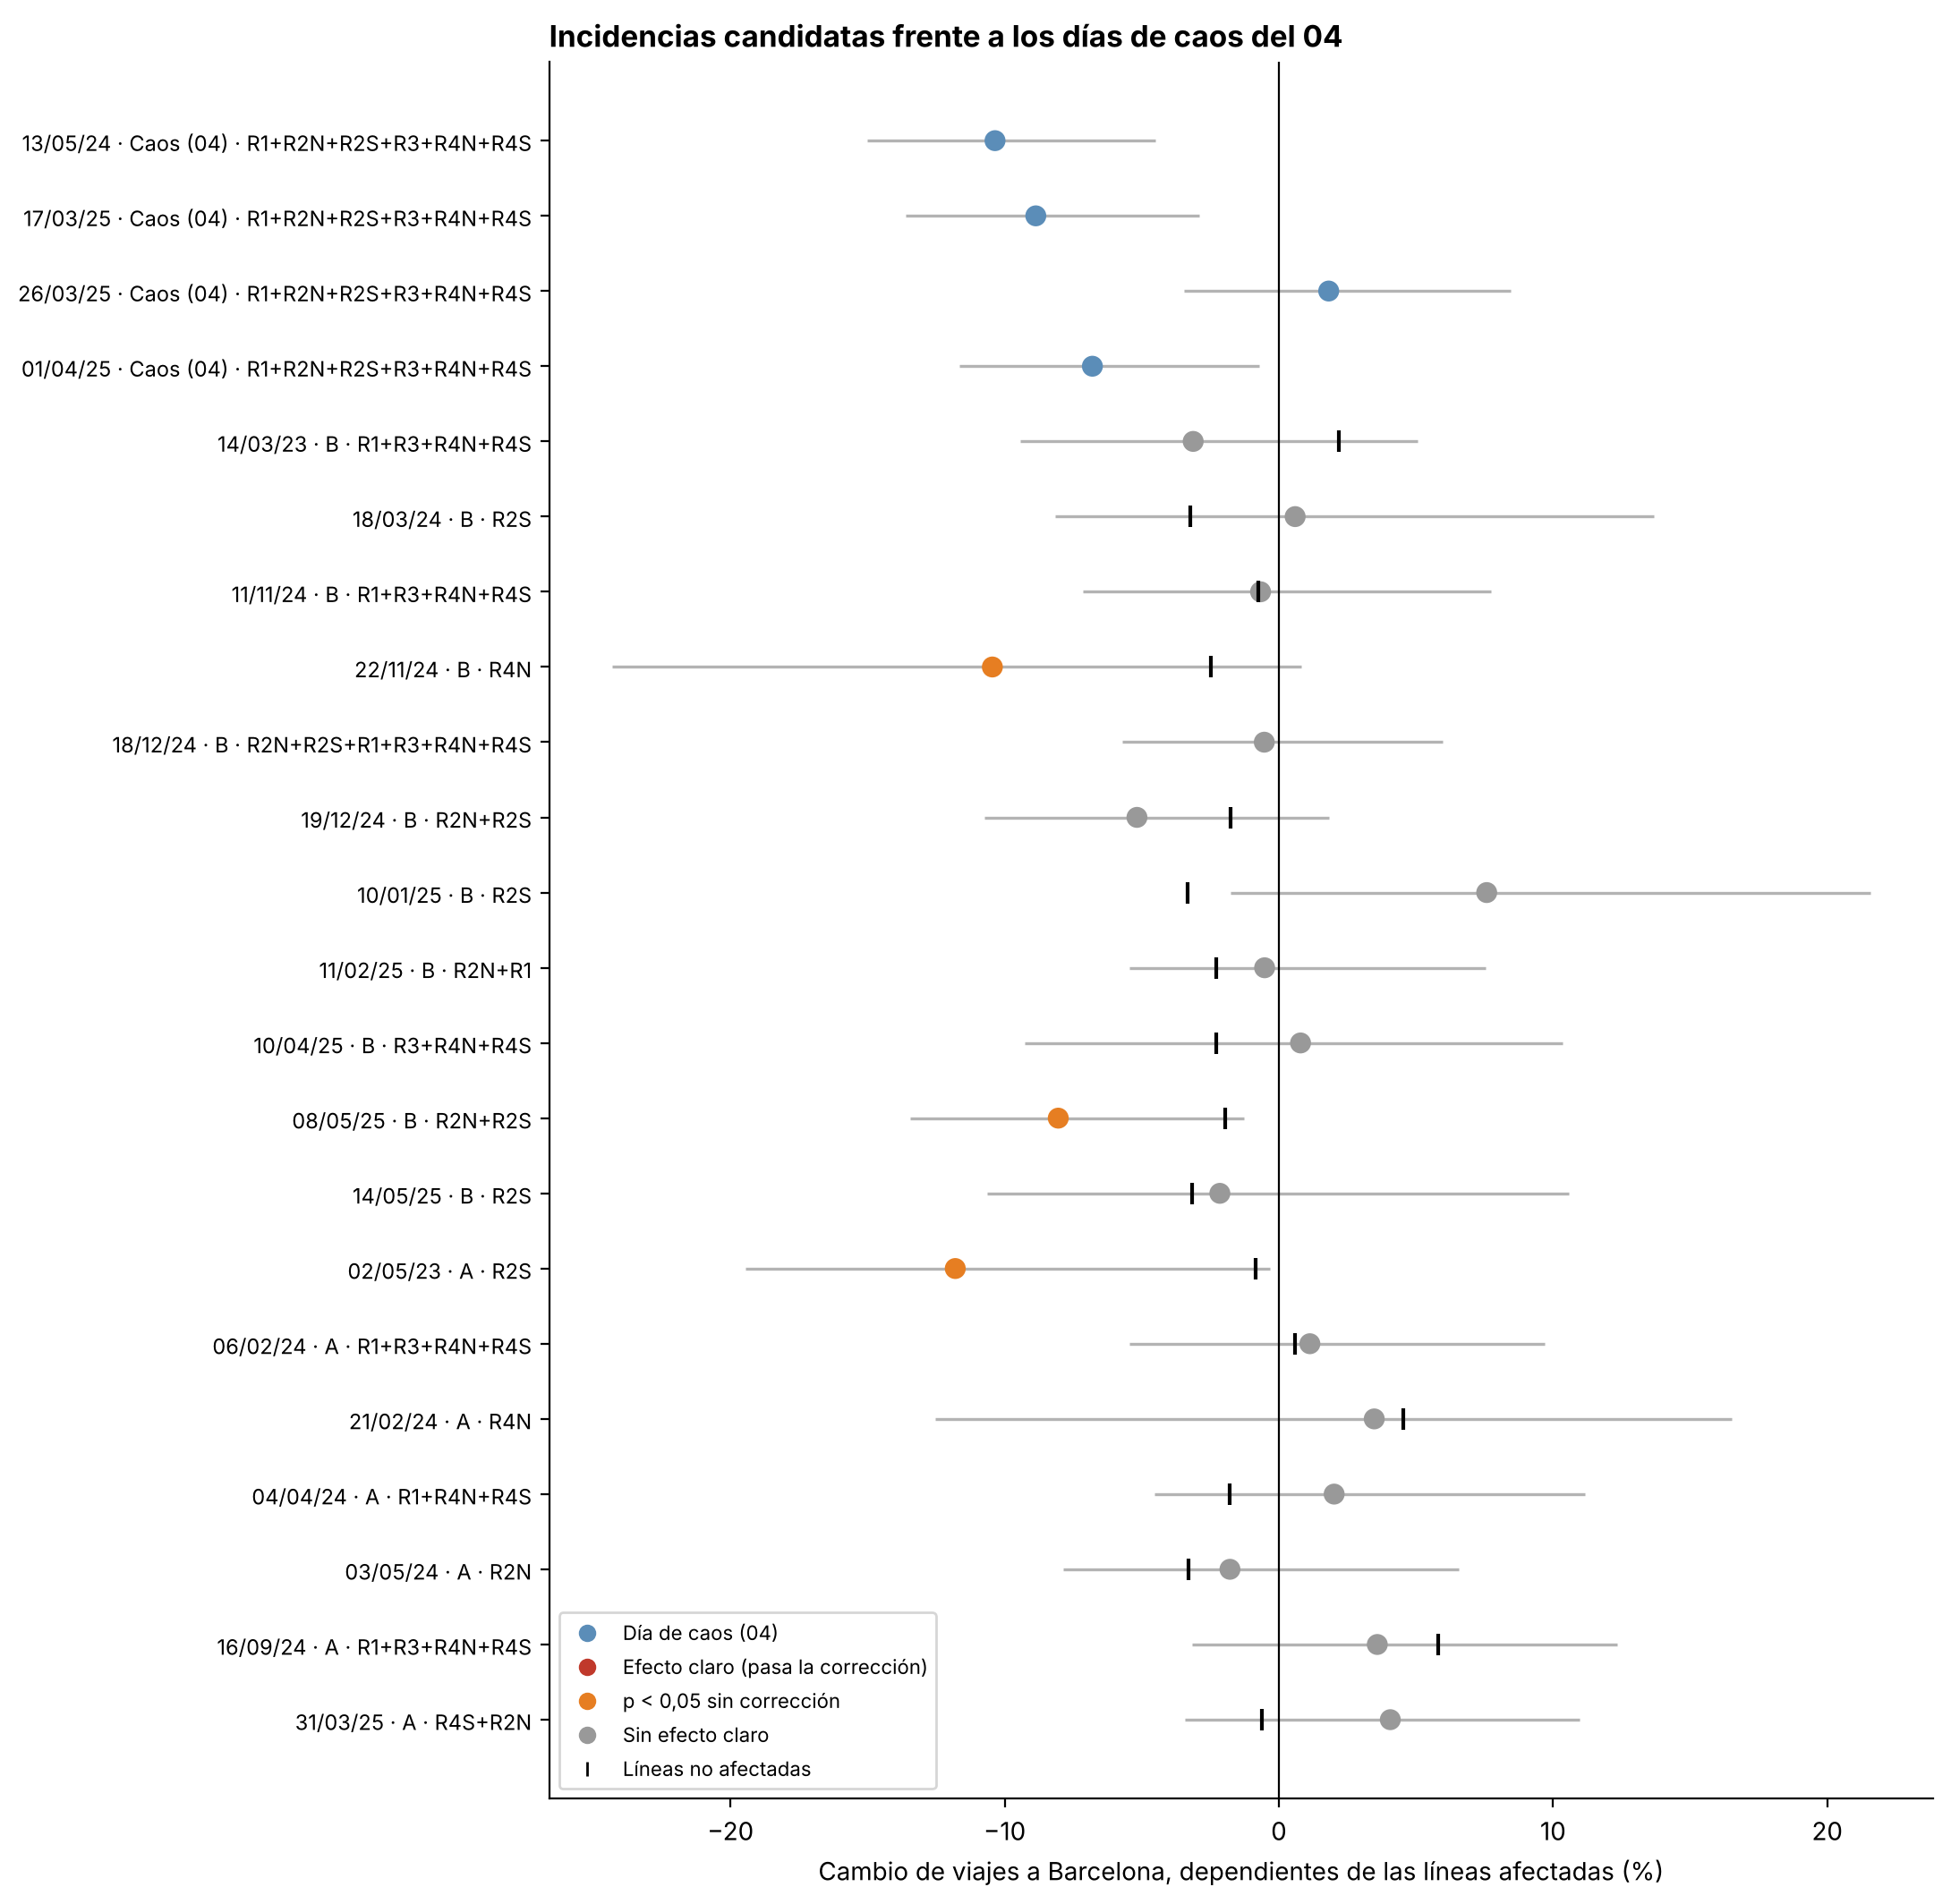

In [9]:
ROJO, NARANJA, GRIS, AZUL = "#C0392B", "#E67E22", "0.6", "#5B8DB8"
s = res.sort_values(["grupo", "fecha"], ascending=[False, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 0.42 * len(s) + 1.5))
y = np.arange(len(s))
col = np.where(s.veredicto.str.startswith("✅"), ROJO, np.where(s.grupo.str.startswith("Caos"), AZUL,
               np.where(s.afect_p < .05, NARANJA, GRIS)))
ax.errorbar(s["afect_%"], y, xerr=[s["afect_%"] - s.afect_lo, s.afect_hi - s["afect_%"]], fmt="none", ecolor="0.7", lw=1.2)
ax.scatter(s["afect_%"], y, c=col, s=55, zorder=3)
ax.scatter(s["no_afect_%"], y, marker="|", c="black", s=80, zorder=3, label="Líneas no afectadas")
ax.axvline(0, color="black", lw=.8)
ax.set_yticks(y, [f"{r.fecha:%d/%m/%y} · {r.grupo} · {r.lineas}" for r in s.itertuples()], fontsize=8.5)
ax.invert_yaxis(); ax.set_xlabel("Cambio de viajes a Barcelona, dependientes de las líneas afectadas (%)")
ax.set_title("Incidencias candidatas frente a los días de caos del 04", loc="left", fontweight="bold")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=l) for c, l in
                   [(AZUL, "Día de caos (04)"), (ROJO, "Efecto claro (pasa la corrección)"), (NARANJA, "p < 0,05 sin corrección"), (GRIS, "Sin efecto claro")]]
          + [Line2D([], [], marker="|", ls="", color="black", label="Líneas no afectadas")], fontsize=8, loc="lower left")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 4. ¿Hay efecto de media en cada grupo?

Aunque un día suelto no sea concluyente, la media de varios días puede serlo. Se compara la media de los efectos de cada
grupo (A, B) con la media de días normales al azar, tomando para cada día un placebo de **su** grupo de municipios.

In [10]:
def efecto_medio(sub, n_sim=20000, seed=0):
    rng = np.random.default_rng(seed); efs, sims = [], []
    for _, r in sub.iterrows():
        codes = list(dep.index[dep.L.map(lambda s: bool(s & set(r.lineas)))])
        sv = V[codes].sum(axis=1, min_count=1)
        efs.append(_ef_log(sv, r.fecha, dias_mismo_tipo(r.fecha)))
        sims.append(rng.choice(placebos(codes), n_sim))
    obs, dist = np.mean(efs), np.mean(sims, axis=0)
    return {"días": len(efs), "efecto_medio_%": round(_pct(obs), 1), "p": round((1 + (dist <= obs).sum()) / (n_sim + 1), 4),
            "IC95": f"[{_pct(obs - np.quantile(dist, .975)):.1f}, {_pct(obs - np.quantile(dist, .025)):.1f}]"}

display(pd.DataFrame({g: efecto_medio(DIAS[DIAS.grupo == g]) for g in ["Caos (04)", "A", "B"]}).T)

,días,efecto_medio_%,p,IC95
Caos (04),4,-6.2,0.0004,"[-8.9, -3.2]"
A,7,-0.0,0.4838,"[-3.6, 3.5]"
B,11,-2.1,0.0622,"[-4.7, 0.7]"


## 5. Ver un día en detalle

Índice de viajes (100 = mediana de los días limpios del mismo tipo) de los dependientes de las líneas afectadas y del
control, 10 días laborables antes y después. Si solo cae la línea roja el día marcado, es la incidencia.

In [11]:
def ver_dia(fecha):
    r = DIAS.set_index("fecha").loc[pd.Timestamp(fecha)]
    codes = list(dep.index[dep.L.map(lambda s: bool(s & set(r.lineas)))])
    lab = V_all.index[~cal.reindex(V_all.index)[["finde", "festivo"]].any(axis=1).values]   # laborables sin festivos
    i = lab.get_loc(pd.Timestamp(fecha)); ventana = lab[max(0, i - 10): i + 11]
    sd, sc = V_all[codes].sum(axis=1, min_count=1), V_all[ctrl].sum(axis=1, min_count=1)
    idx = pd.DataFrame({d: {"dep": sd[d] / sd.loc[dias_mismo_tipo(d)].median() * 100,
                            "ctrl": sc[d] / sc.loc[dias_mismo_tipo(d)].median() * 100}
                        for d in ventana if d.year in modelos and np.isfinite(vol_ctrl.get(d, np.nan))}).T
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(idx.index, idx.dep, "-o", color=ROJO, ms=4, label=f"Dependientes {'+'.join(r.lineas)} ({len(codes)} mun.)")
    ax.plot(idx.index, idx.ctrl, "-o", color="0.55", ms=4, label="Sin Rodalies (control)")
    ax.axvline(pd.Timestamp(fecha), color=ROJO, ls=":", lw=1); ax.axhline(100, color="black", lw=.6)
    no_limpio = [d for d in idx.index if d not in LIMPIOS]
    ax.scatter(no_limpio, idx.loc[no_limpio, "dep"], facecolor="white", edgecolor=ROJO, zorder=3, s=30)
    ax.set_title(f"{pd.Timestamp(fecha):%d/%m/%Y} · {r.descripcion}", loc="left", fontweight="bold", fontsize=10)
    import matplotlib.dates as mdates; ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_ylabel("Índice (100 = día normal)"); ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

Los puntos vacíos son días no limpios (otras incidencias, eventos, lluvia…). Cambiad la fecha para ver otro día:

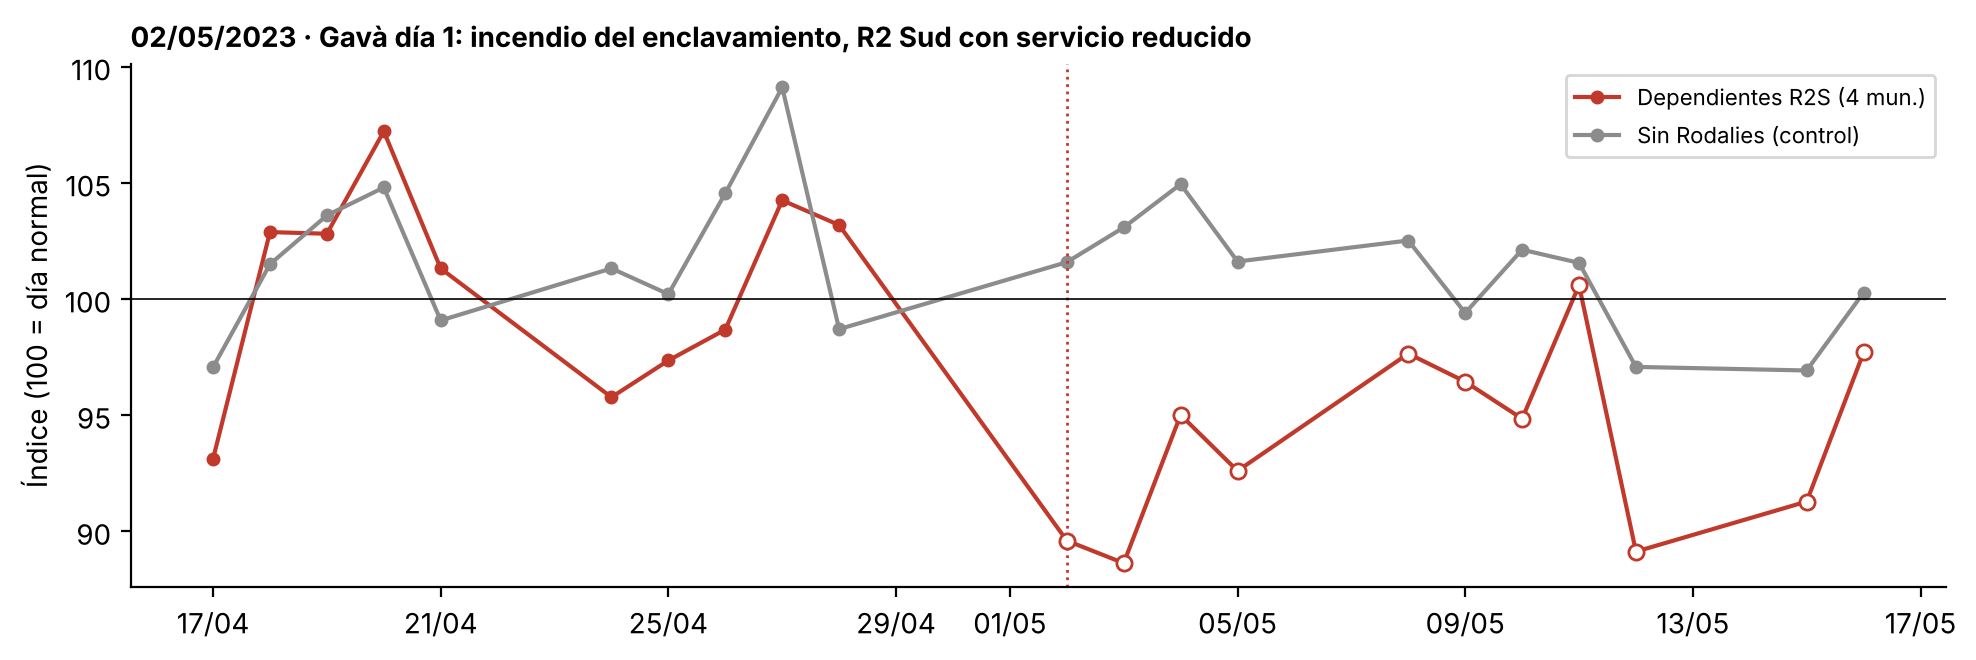

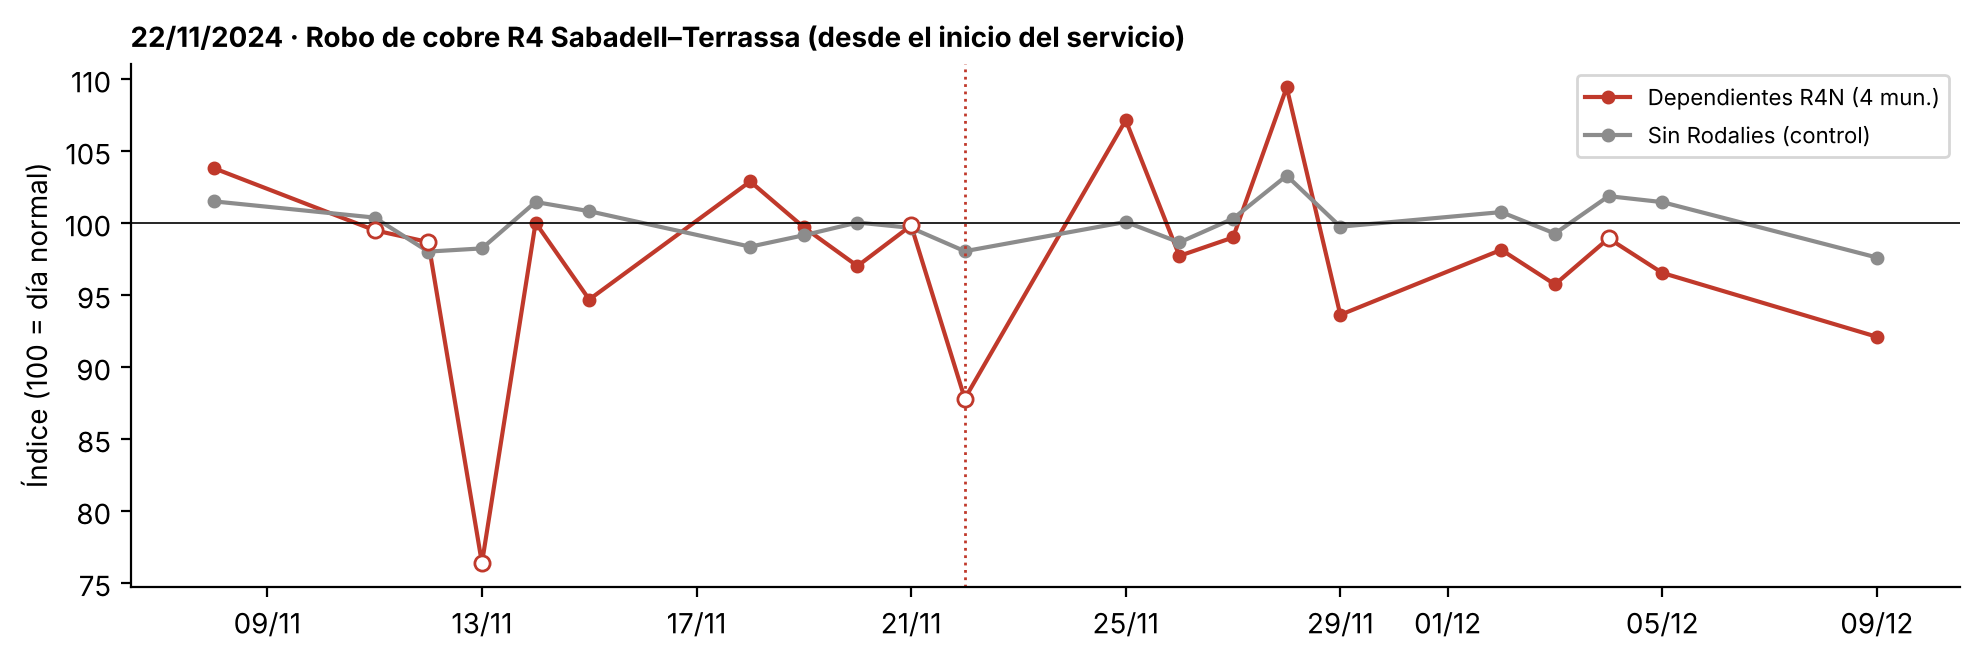

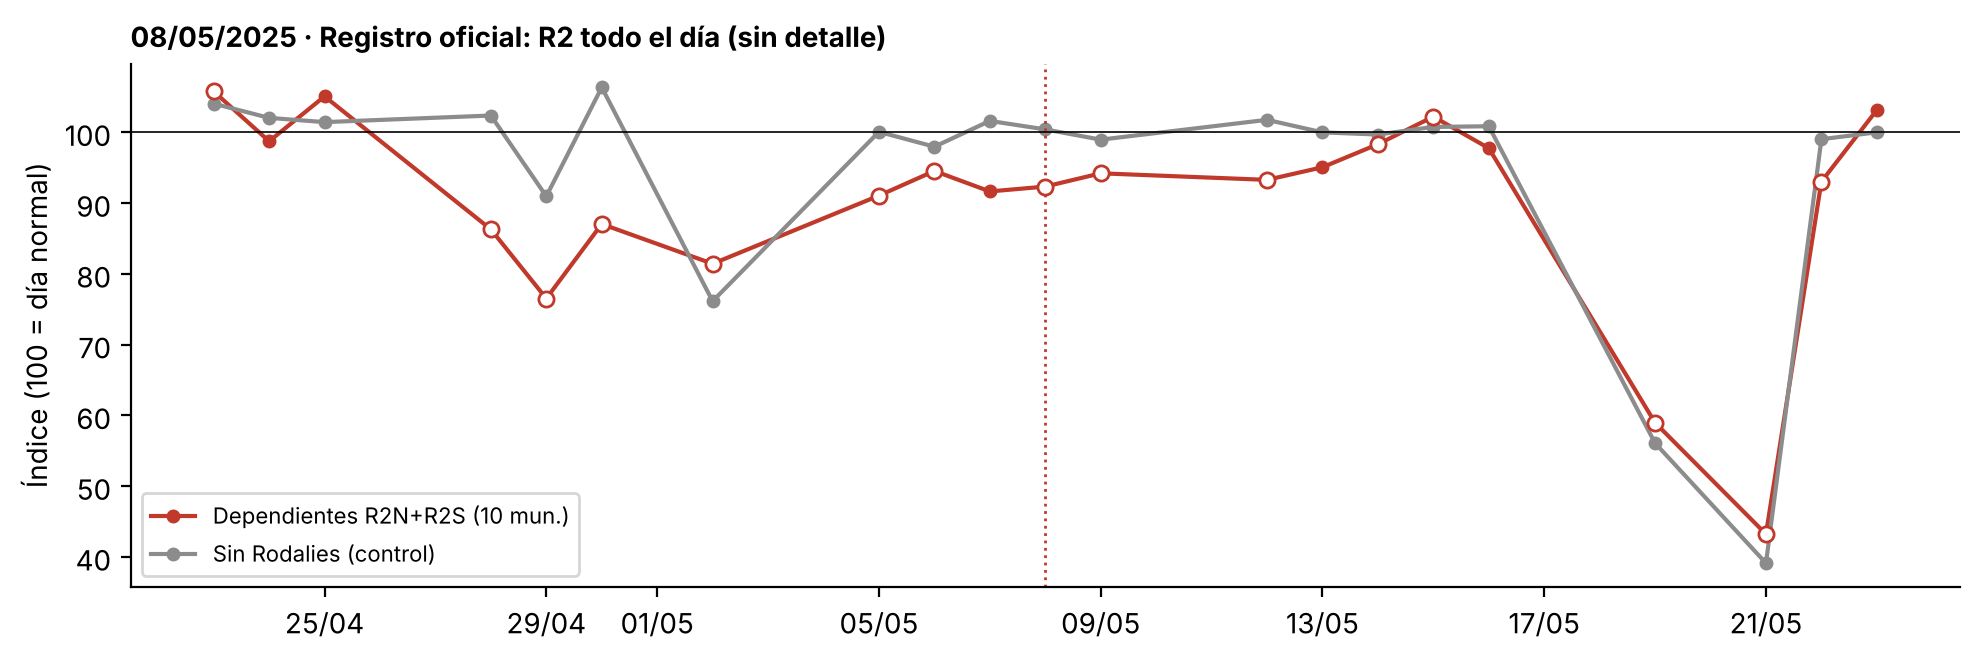

In [12]:
for f in res.loc[res.veredicto.str.startswith(("✅", "🔶", "⚠️")), "fecha"]:
    ver_dia(f)

## 6. Conclusión

*(Rellenar después de ejecutar.)* Las incidencias con **✅ añadir** pasan los tres criterios y se pueden incorporar al
notebook 04 (en `DIAS_CAOS` y en `TRAMOS`). Las **🔶 al límite** se pueden mencionar en la memoria como indicio, pero no se
añaden. Las **⚠️ caen todos** indican que ese día pasó algo general (no la incidencia).